# CPAS STEM Education - Typhoon Simulation & Visualization
Copyright © 2023-2026 ClusterTech Limited. For authorized use.

# 1 Credentials

Your CPAS Data Credentials and Data path

**Click the "Visualization" menu button on the CPAS platform to generate your credential** (valid for a few hours, do again if expired).

**Copy your credentials.**


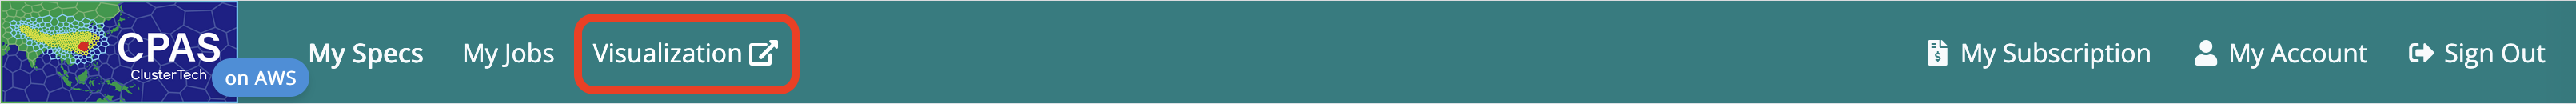

A pop-up tab would appear, if not, allow it in your browser (via some browser settings).

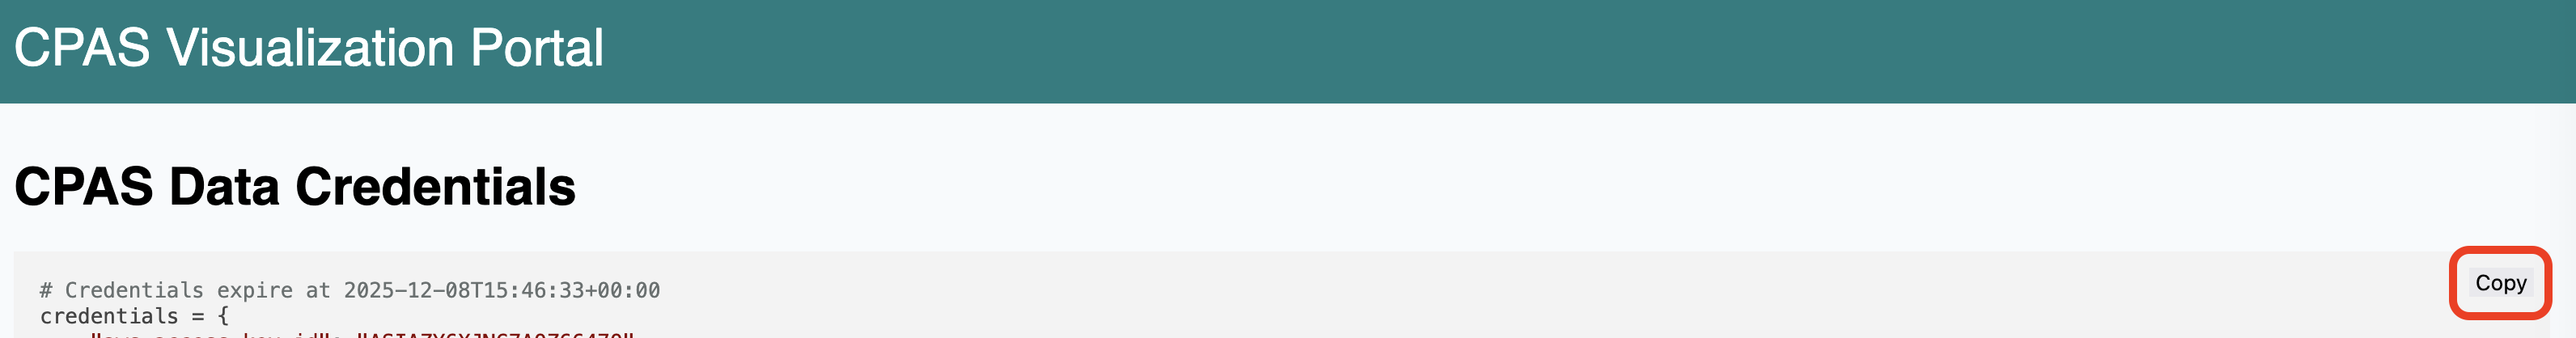

The CPAS Data Credentials are something like:
```
# Credentials expire at YYYY-MM-DD HH:mm:ss
credentials = {
    "aws_access_key_id": "",
    "aws_secret_access_key": "",
    "aws_session_token": "",
    "region_name": "us-east-1",
}
data_path = ""
```
**Paste the copied code to the empty cell below**. Then, run it and the cells below.

In [ ]:
# For the flexibility of using your jobs or demo data below
my_data_path = data_path
demo_path = "s3://demodata.ac.cpas.earth/cpas_data"

# 2 Packages

Install dependency

In [ ]:
# The following packages should works with Collab (tested 2026-11-13);
# if something wrong, need to test and specify matching package versions with the provided python runtime environment
%pip install s3fs universal_pathlib uxarray[complete] jupyter_bokeh

# 3 Yours or Demo

Choose: **Your Jobs** or **Demo data**

If you want to visualize **your job**, keep code as

`use_demo_data = False`.


If you want to visualize CPAS **demo data** instead, change code to

`use_demo_data = True`.

In [ ]:
# Change this value to choose to visualize your job or demo data
use_demo_data = False  # choices: True, False

if use_demo_data:
    data_path = demo_path
else:
    data_path = my_data_path

data_path

## Accessing CPAS data

In [ ]:
import upath

root = upath.UPath(data_path, client_kwargs=credentials)
root

# 4 Select Mesh


In [ ]:
import ipywidgets
import json

dirlist = root.glob("projects/*/jobs/*/param.json")
mesh_dir = ipywidgets.Dropdown(description="Select generated mesh: ",
                               style={'description_width': 'initial'},
                               layout=ipywidgets.Layout(width='90%'),
                               options=[
                                   (f'{json.load(p.open())["gen_job_name"]} ({p.parent})', p.parent)
                                   for p in dirlist
                               ])
mesh_dir

# Your jobs: Select with the name of your Mesh Generation job
# Demo data: Select "Mawar2023" for the fastest demo

In [ ]:
mfiles = list(mesh_dir.value.glob("*.nc"))
print(f"Data files in the selected directory: {[p.name for p in mfiles]}")

In [ ]:
import uxarray as ux

mesh_path = mesh_dir.value / "static.nc"  # Some demo data provide only static.nc (after Real Simulation)
if not mesh_path.exists():
    mesh_path = mesh_dir.value / "grid.nc"  # Mesh Generation produces grid.nc
grid = ux.open_grid(mesh_path.open("rb"))
grid

### Plot Mesh

In [ ]:
# Define your lat-lon range: (min, max)
minlon, maxlon = (90, 150)  # Example: 100°E to 140°E
minlat, maxlat = (0, 40)  # Example: 0°N to 40°N
my_width = 700

# Code below
import cartopy.crs as ccrs
import geoviews.feature as gf

proj = ccrs.PlateCarree()

# Plot the grid and overlay coastlines with '*'
plot = grid.plot(
    backend='matplotlib',
    projection=proj,
    xlim=(minlon, maxlon),
    ylim=(minlat, maxlat),
    width=my_width
) * gf.coastline(projection=proj)

plot

# EXTRA Challenges

No need to complete them if you feel the above is enough.

### Plot mesh (Zoomable, needs browser support)

In [ ]:
# Define your lat-lon range: (min, max)
minlon, maxlon = (90, 150)  # Example: 100°E to 140°E
minlat, maxlat = (0, 40)  # Example: 0°N to 40°N

# Code below
import cartopy.crs as ccrs
grid.plot(tiles="EsriWorldTopo",
          backend='bokeh',
          projection=ccrs.GOOGLE_MERCATOR,
          xlim=(minlon, maxlon),
          ylim=(minlat, maxlat),
)